# Have temperatures been rising in Redmond?

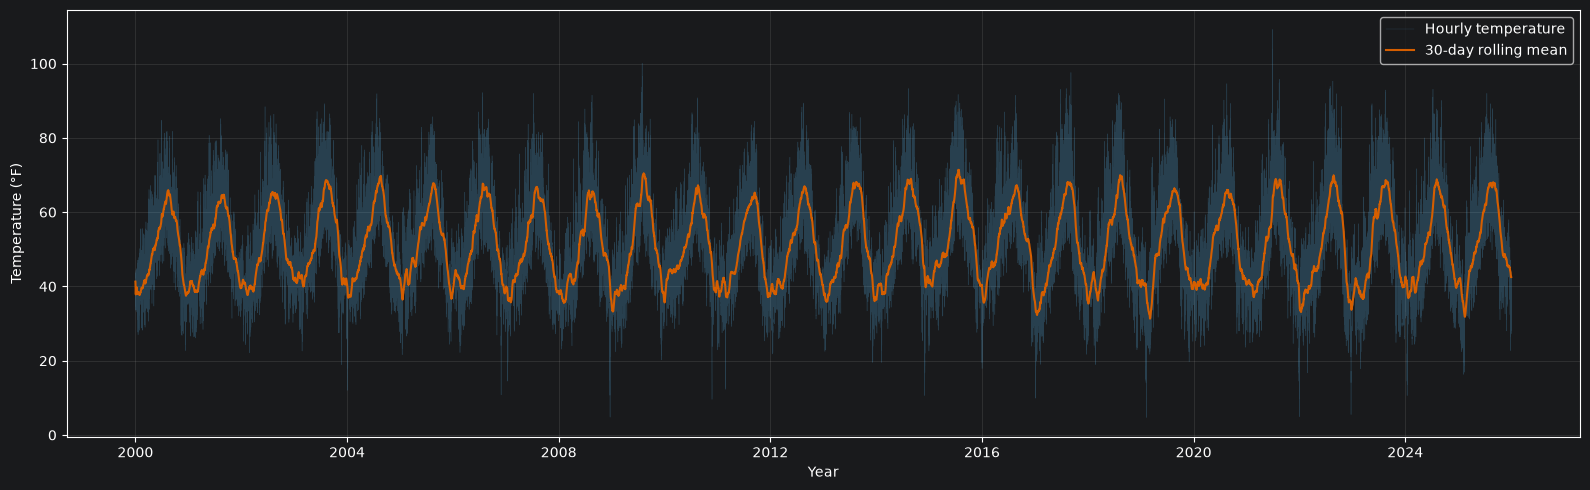

In [100]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

colors = [
    '#0072B2', '#E69F00', '#009E73', '#D55E00',
    '#CC79A7', '#56B4E9', '#F0E442', '#332288',
    '#882255', '#44AA99', '#117733', '#AA4499',
    '#88CCEE', '#DDCC77', '#999933', '#CC6677',
    '#661100', '#6699CC', '#AA4466', '#228833',
    '#EE7733', '#BBBBBB', '#4477AA', '#EE3377',
    '#66CCEE', '#000000'
]

df = pd.read_csv("data/open-meteo_redmond2000-2025_temperature.csv")
df['time'] = pd.to_datetime(df['time'])
df = df.rename(columns={'temperature_2m (°F)':'temperature_2m'})
df = df.set_index('time')
plt.figure(figsize = (16,5))
plt.plot(
    df.index, df['temperature_2m'],
    color='#56B4E9',
    linewidth=0.3,
    alpha=0.25,
    label='Hourly temperature'
)
rolling = df['temperature_2m'].rolling('30D').mean()
plt.plot(
    rolling.index, rolling,
    color='#D55E00',
    linewidth=1.5,
    label='30-day rolling mean'
)
plt.xlabel('Year')
plt.ylabel('Temperature (°F)')
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

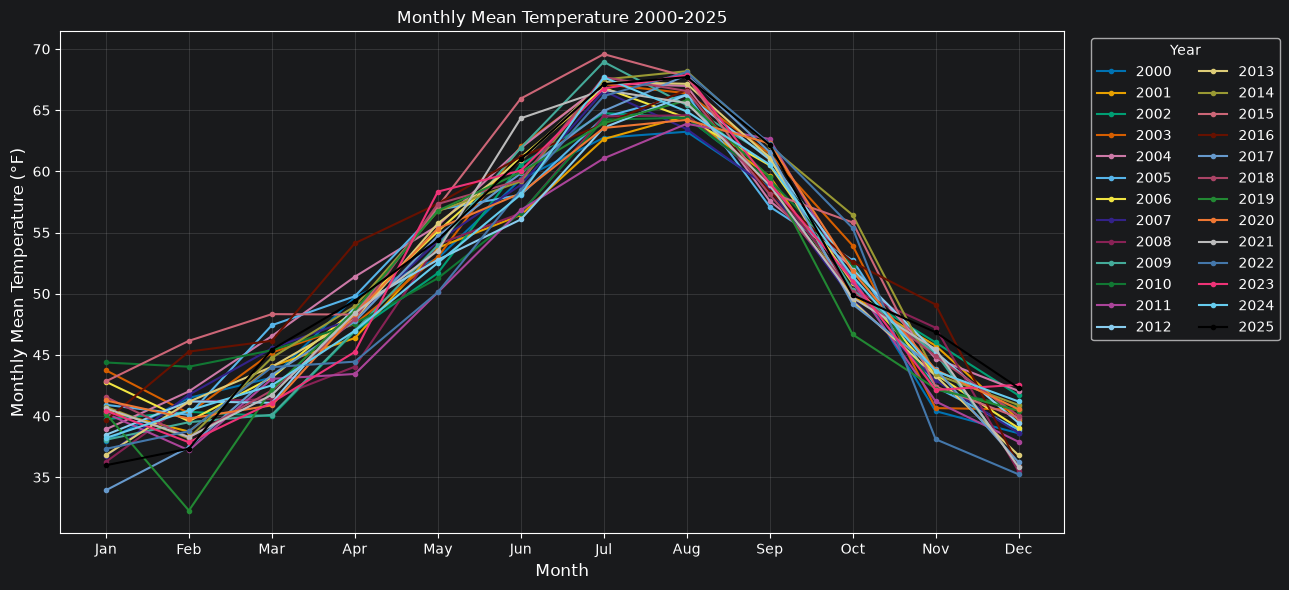

In [101]:
df['year'] = df.index.year
df['month'] = df.index.month

monthlyAvg = df.groupby(['year', 'month'])['temperature_2m'].mean().unstack(level=0)

plt.figure(figsize=(13, 6))
for i,year in enumerate(monthlyAvg.columns):
    plt.plot(
        monthlyAvg.index,
        monthlyAvg[year],
        color=colors[i],
        linewidth=1.5,
        marker='o',
        markersize=3,
        label=str(year)
    )

plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Monthly Mean Temperature (°F)', fontsize=12)

plt.title('Monthly Mean Temperature 2000-2025')

plt.legend(
    title='Year',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=2
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
#plt.plot(
#    monthly.index,
#    monthly.values,
#    color='#0072B2',
#    marker='o',
#    linewidth=2
#)
#
#plt.xticks(range(1, 13))
#plt.xlabel('Month')
#plt.ylabel('Mean temperature (°C)')
#plt.title('25-Year Monthly Temperature Climatology')
#plt.grid(alpha=0.3)
#plt.tight_layout()
#plt.show()

In [2]:
monthlyMin = df.groupby(['year','month'])['temperature_2m'].min().unstack(level=0)
monthlyMax = df.groupby(['year','month'])['temperature_2m'].max().unstack(level=0)

for i,year in enumerate(monthlyMin.columns):
    plt.plot(
        monthlyMin.index,
        monthlyMin[year],
        color=colors[i],
        linewidth=1.5,
        marker='o',
        markersize=3,
        label=str(year)
    )
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Monthly Min Temperature (°F)', fontsize=12)

plt.title('Monthly Min Temperature 2000-2025')

plt.legend(
    title='Year',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=2
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

for i,year in enumerate(monthlyMax.columns):
    plt.plot(
        monthlyMax.index,
        monthlyMax[year],
        color=colors[i],
        linewidth=1.5,
        marker='o',
        markersize=3,
        label=str(year)
    )
plt.xticks(
    range(1, 13),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Monthly Max Temperature (°F)', fontsize=12)

plt.title('Monthly Max Temperature 2000-2025')

plt.legend(
    title='Year',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    ncol=2
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

NameError: name 'df' is not defined